In [1]:
import torch
import numpy as np
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import torchvision
import tqdm
import glob
from PIL import Image
import seaborn as sns
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

import sys
sys.path.append('../../vision')

import datasets
import training_loop
import losses
import models
import optimizers

if torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')
print(device)
s3d_or_vit = 'vit'
labels = pd.read_csv("../../labels/semi_cleaned_labels_3_features_2024-10-21.csv")
labels = labels.drop(columns=['MRN','SURGERY_DATE'])

new_labels = labels.replace('nan', np.nan)
new_labels = new_labels.replace('nc', np.nan)

# drop nans:
new_labels.dropna(inplace=True) # needs to happen before sorting into pre and post

new_labels_pre = new_labels[['ACC_NUM','LVEF_pre','RVSF_pre','TR_pre']]
new_labels_pre.columns = ['ACC_NUM','LVEF','RVSF','TR']
new_labels_pre['prepost'] = 0

new_labels_post = new_labels[['ACC_NUM','LVEF_post','RVSF_post','TR_post']]
new_labels_post.columns = ['ACC_NUM','LVEF','RVSF','TR']
new_labels_post['prepost'] = 1

new_labels = pd.concat([new_labels_pre, new_labels_post])
new_labels.reset_index(drop=True, inplace=True)

new_labels['LVEF'] = new_labels['LVEF'].astype(float)/100
new_labels['RVSF'] = new_labels['RVSF'].astype(float)/6
new_labels['TR'] = new_labels['TR'].astype(float)/7

ground_truths = pd.read_csv("../../labels/500_reports_groundtruth.csv")['ACC_NUM']

# drop nans:
new_labels.dropna(inplace=True)

ground_truths = list(ground_truths.astype(float))

training_labels = new_labels.drop(new_labels[new_labels['ACC_NUM'].isin(ground_truths)].index)
evaluation_labels = new_labels.drop(new_labels[~new_labels['ACC_NUM'].isin(ground_truths)].index) # not quite correct, but probably good enough until we clean the gt dataset

view_prediction_csvs = glob.glob("../../labels/view_predictions/cycle_*/predictions_all_cycle_*.csv", recursive=True)
predictions = []
for cycle_preds in view_prediction_csvs:
    cycle = pd.read_csv(cycle_preds)
    predictions.append(cycle.loc[cycle['prediction'].isin([3,4,5,6,7,8,9])]) # If filtering by view - currently all 2,4,5 chamber with/without color
    predictions.append(cycle) # If not filtering by view

all_cycles = pd.concat(predictions)
all_cycles = all_cycles.reset_index()
val_cycles = all_cycles.sample(frac=0.01, random_state=0)
train_cycles = all_cycles.drop(val_cycles.index)

val_cycles = val_cycles.reset_index()
train_cycles = train_cycles.reset_index()
test_cycles = train_cycles.copy()

print(len(train_cycles))
removals = []
for i in tqdm.tqdm(range(len(train_cycles['clip_path']))):
    try:
        if int(os.path.basename(os.path.split(train_cycles['clip_path'].iloc[i])[0])) not in list(training_labels['ACC_NUM']):
        # if int(os.path.basename(os.path.split(train_cycles['clip_path'].iloc[i])[0])) in ground_truths:
            removals.append(i)
    except:
        removals.append(i)
train_cycles = train_cycles.drop(removals)
print(len(train_cycles))

print(len(val_cycles))
removals = []
for i in tqdm.tqdm(range(len(val_cycles['clip_path']))):
    try:
        if int(os.path.basename(os.path.split(val_cycles['clip_path'].iloc[i])[0])) not in list(training_labels['ACC_NUM']):
        # if int(os.path.basename(os.path.split(val_cycles['clip_path'].iloc[i])[0])) in ground_truths:
            removals.append(i)
    except:
        removals.append(i)
        
val_cycles = val_cycles.drop(removals)
print(len(val_cycles))
train_cycles = train_cycles.reset_index(drop=True)
val_cycles = val_cycles.reset_index(drop=True)

removals = []
for i in tqdm.tqdm(range(len(test_cycles['clip_path']))):
    try:
        if int(os.path.basename(os.path.split(test_cycles['clip_path'].iloc[i])[0])) not in list(evaluation_labels['ACC_NUM']):
        # if int(os.path.basename(os.path.split(val_cycles['clip_path'].iloc[i])[0])) in ground_truths:
            removals.append(i)
    except:
        removals.append(i)
        
test_cycles = test_cycles.drop(removals)
print(len(test_cycles))
test_cycles = test_cycles.reset_index(drop=True)

train_clips = list(train_cycles['clip_path'])
val_clips = list(val_cycles['clip_path'])
test_clips = list(test_cycles['clip_path'])

prepost_pred = pd.read_csv('/home/trevor/repos/deep_TEE/labels/preop_postop_prediction.csv')
acc_nums = [prepost_pred['clip_path'][i].split('/')[0] if type(prepost_pred['clip_path'][i])==str else '' for i in range(len(prepost_pred['clip_path']))]
dcm_nums = [prepost_pred['clip_path'][i].split('/')[-1] if type(prepost_pred['clip_path'][i])==str else ''  for i in range(len(prepost_pred['clip_path']))]
prepost_pred['ACC_NUM'] = acc_nums
prepost_pred['DCM_NUM'] = dcm_nums

if s3d_or_vit == 's3d':
    train_transforms = datasets.TransformsComposed('train', size=(224,224))
    valtest_transforms = datasets.TransformsComposed('valtest', size=(224,224))
elif s3d_or_vit == 'vit':
    train_transforms = datasets.TransformsComposed('train', size=(128,128))
    valtest_transforms = datasets.TransformsComposed('valtest', size=(128,128))
features = ['LVEF','RVSF','TR']
train_dataset = datasets.VideoDataset(clip_paths=train_clips, labels_df=training_labels, features=features, time_df=prepost_pred, transform=train_transforms, duration=32, skip=2)
val_dataset = datasets.VideoDataset(clip_paths=val_clips, labels_df=training_labels,  features=features, time_df=prepost_pred, transform=valtest_transforms, duration=32, skip=2)
test_dataset = datasets.VideoDataset(clip_paths=test_clips, labels_df=evaluation_labels, features=features, time_df=prepost_pred, transform=valtest_transforms, duration=32, skip=2)

cuda:0


/tmp/ipykernel_1456218/1453848463.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_labels_pre['prepost'] = 0
/tmp/ipykernel_1456218/1453848463.py:46: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_labels_post['prepost'] = 1


756462


100%|██████████| 756462/756462 [05:38<00:00, 2233.99it/s]


607123
7641


100%|██████████| 7641/7641 [00:03<00:00, 2424.77it/s]


6099


100%|██████████| 756462/756462 [00:29<00:00, 25927.42it/s]


46064


# Evaluation

In [2]:
# # load model
# model = YourModelClass()  # Replace with your model architecture
# model.load_state_dict(torch.load('my_model.pth'))
# model.eval()  # Set the model to evaluation mode
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/test_vit_128_32_1_0_3feature_nchamberfilter_test2/*.pt'))[100])['net'].to(device).eval()
# model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/test_vit_128_32_1_0_3feature_anyview_test1/*.pt'))[62])['net'].to(device).eval()

tensor([[0.6023, 0.0016, 0.3161]], device='cuda:0')
tensor([[0.6000, 0.0000, 0.0000]], dtype=torch.float64)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


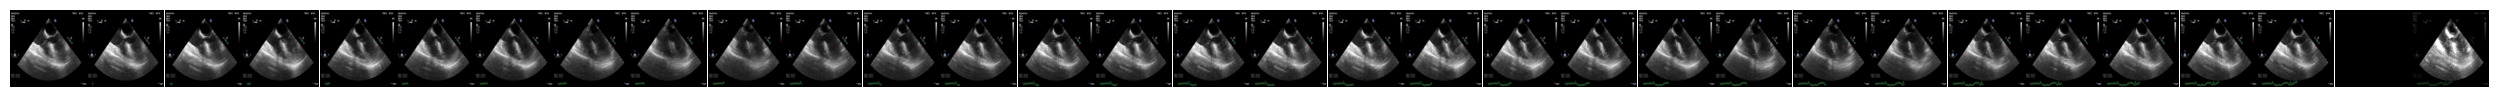

In [3]:
with torch.no_grad():
    # Visualize the images
    idx = np.random.randint(len(test_dataset))
    parcel = test_dataset[idx]['data']

    with torch.no_grad():
        print(model.eval()(test_dataset[idx]['data'].unsqueeze(0).to(device)))
        print(test_dataset[idx]['label'])

    fig, ax = plt.subplots(1,parcel.shape[1], figsize=(parcel.shape[1],1), frameon=False)
    for i in range(parcel.shape[1]):
        ax[i].imshow(parcel[:,i,:,:].permute(1,2,0))
        ax[i].set_axis_off()
    plt.subplots_adjust(wspace=0, hspace=0)

    # Accumulated motion image
    plt.imshow(torch.clamp(torch.sum(torch.abs(torch.diff(parcel,dim=1)), dim=1).permute(1,2,0) / parcel.shape[1] * 10, 0,255))

tensor([[0.5406, 0.3132, 0.3169]], device='cuda:0')
tensor([[0.5000, 0.0000, 1.0000]], dtype=torch.float64)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


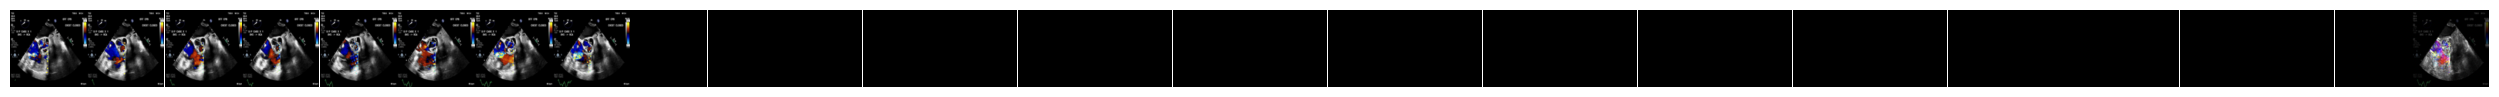

In [4]:
# Visualize the images
idx = np.random.randint(len(test_dataset))
parcel = test_dataset[idx]['data']

with torch.no_grad():
    print(model(test_dataset[idx]['data'].unsqueeze(0).to(device)))
    print(test_dataset[idx]['label'])

fig, ax = plt.subplots(1,parcel.shape[1], figsize=(parcel.shape[1],1), frameon=False)
for i in range(parcel.shape[1]):
    ax[i].imshow(parcel[:,i,:,:].permute(1,2,0))
    ax[i].set_axis_off()
plt.subplots_adjust(wspace=0, hspace=0)

# Accumulated motion image
plt.imshow(torch.clamp(torch.sum(torch.abs(torch.diff(parcel,dim=1)), dim=1).permute(1,2,0) / parcel.shape[1] * 10, 0,255))

## No Aggregation

In [3]:
y = []
yp = []
maxsample = 1000

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(test_dataset), maxsample))):
        # if test_dataset[idx]['label'] != test_dataset[idx]['label']:
        #     continue
        # if test_dataset[idx]['label'] > 1:
        #     continue
        y.append(test_dataset[idx]['label'].numpy().squeeze())
        yp.append(model(test_dataset[idx]['data'].unsqueeze(0).to(device)).cpu().numpy().squeeze())
       
results = np.concatenate((np.array(y),np.array(yp)), axis=1)
df = pd.DataFrame(results, columns=[f'{feature}_label' for feature in features] + [f'{feature}_pred' for feature in features])

  0%|          | 0/1000 [00:00<?, ?it/s]

100%|██████████| 1000/1000 [02:31<00:00,  6.62it/s]


Text(0.45, 0, "Pearson's r = 0.23")

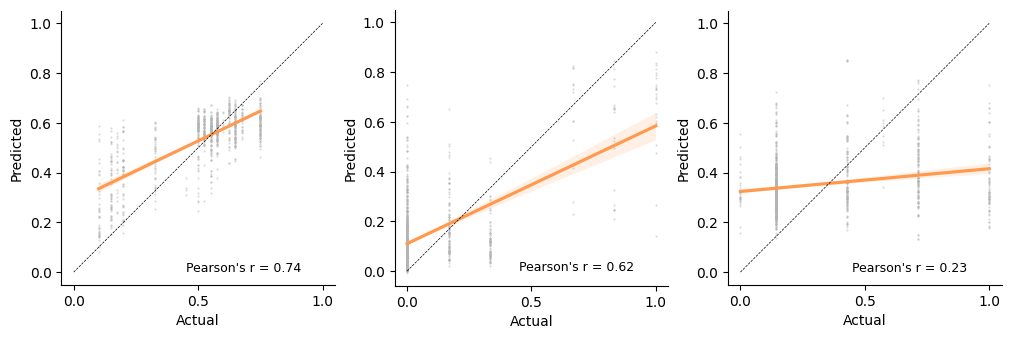

In [4]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

Text(0.45, 0, "Pearson's r = 0.23")

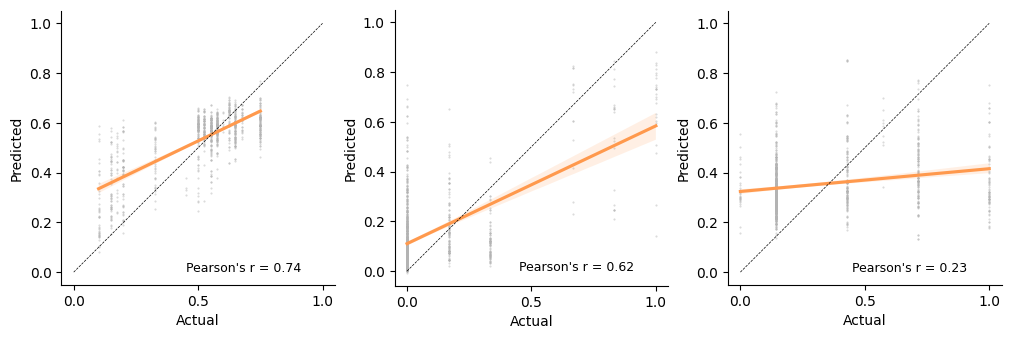

In [5]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

Text(0.45, 0, "Pearson's r = 0.23")

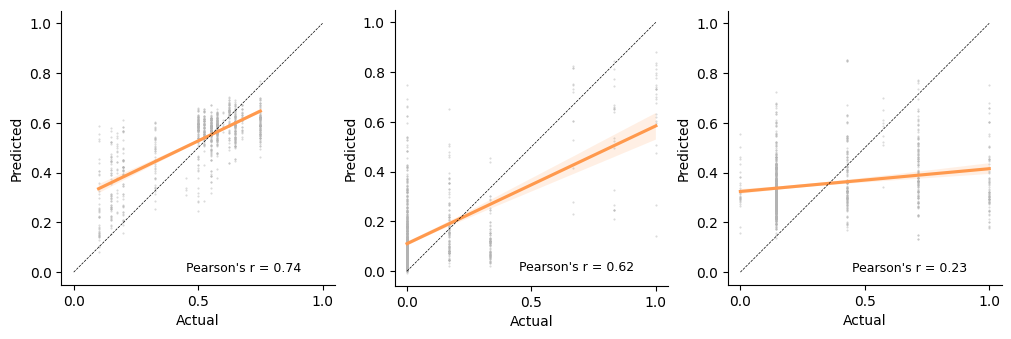

In [6]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

Text(0.45, 0, "Pearson's r = 0.23")

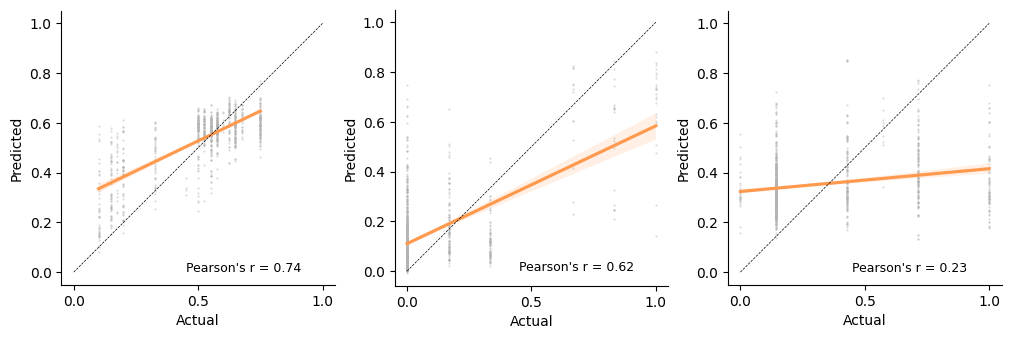

In [7]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

## Aggregation over a clip

In [8]:
class EvaluationDataset(torch.utils.data.Dataset):

    def __init__(self, clips, labels=None, transform=None, duration=32, skip=1, autobatch=True):
        self.clips = clips
        self.transform = transform
        self.duration = duration
        self.skip = skip
        self.autobatch = autobatch
        self.labels = labels

    def __len__(self):
        return len(self.clips)

    def __getitem__(self, idx):
        data = self.__read_images(self.clips[idx], self.duration, self.skip)
        
        if self.transform:
            data = self.transform(data)
            
        data = data.permute(0,2,1,3,4) # reshape to (B,C,T,H,W)
        
        if self.labels:
            label = labels[idx]
            return {'data':data, 'label':label}
        else:
            return {'data':data}
    
    def __read_images(self, path, duration=32, skip=1):
        frame_paths = glob.glob(path+'/*')
        if not self.autobatch:
            if len(frame_paths) <= duration * skip:
                start = 0
                stop = len(frame_paths)
                pad = (duration * skip - stop) // skip
            else:
                start = np.random.randint(0, len(frame_paths) - duration * skip + 1)
                stop = start + duration * skip
                pad = 0
            frames = []
            for frame in sorted(frame_paths)[start:stop:skip]:
                frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
            for i in range(pad):
                frames.append(torch.zeros_like(frames[-1]))
            frames = torch.stack(frames, dim=0)
            batches = frames
        else:
            batches = []
            for batch in range(int(np.ceil(len(frame_paths)/skip/duration))):
                start = batch * skip * duration
                stop = min((batch + 1) * skip * duration, len(frame_paths))
                pad = min(0, len(frame_paths) - ((batch + 1) * skip * duration))
                
                frames = []
                for frame in sorted(frame_paths)[start:stop:skip]:
                    frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
                for i in range(-pad//2):
                    frames.append(torch.zeros_like(frames[-1]))
                frames = torch.stack(frames, dim=0)
                batches.append(frames)
            batches = torch.stack(batches, dim=0)
        return batches

In [9]:
paths = [test_dataset.clip_paths[i] for i in range(len(test_dataset))]
labels = [test_dataset[i]['label'] for i in range(len(test_dataset))]

In [10]:
eval_dataset = EvaluationDataset(paths, labels=labels, transform=valtest_transforms, duration=32, skip=2, autobatch=True)

In [11]:
# y = []
# yp = []
# maxsample = 10000

# with torch.no_grad():
#     for idx in tqdm.tqdm(range(min(len(eval_dataset), maxsample))):
#         y.append(eval_dataset[idx]['label'])
#         yp.append(torch.mean(model(eval_dataset[idx]['data'].to(device))).item())
# df = pd.DataFrame({'y':y, 'yp':yp})

In [12]:
y = []
yp = []
maxsample = 100000

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(test_dataset), maxsample))):
        # if test_dataset[idx]['label'] != test_dataset[idx]['label']:
        #     continue
        # if test_dataset[idx]['label'] > 1:
        #     continue
        y.append(eval_dataset[idx]['label'].numpy().squeeze())
        # yp.append(model(eval_dataset[idx]['data'].unsqueeze(0).to(device)).cpu().numpy().squeeze())
        yp.append(model(eval_dataset[idx]['data'].to(device)).cpu().numpy().squeeze())
       
results = np.concatenate((np.array(y),np.array([np.mean(pred, axis=0) if len(pred.shape) == 2 else pred for pred in yp])), axis=1)

df = pd.DataFrame(results, columns=[f'{feature}_label' for feature in features] + [f'{feature}_pred' for feature in features])

df = df.drop(np.where(df['LVEF_label'] > 1)[0])

100%|██████████| 46064/46064 [44:15<00:00, 17.35it/s]  


In [13]:
# fig, ax = plt.subplots(1,2, figsize=(6,3), layout="constrained")
# for a in ax:
#     a.spines[['right', 'top']].set_visible(False)
#     a.set_aspect('equal')
#     a.set_xticks([0,0.5,1])

# from scipy import stats
# res = stats.pearsonr(y, yp)
# sns.regplot(data=df, x="y", y="yp", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
# ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[0].set_aspect('equal')
# ax[0].set_ylabel('Predicted')
# ax[0].set_xlabel('Actual')
# ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

Text(0.45, 0, "Pearson's r = 0.31")

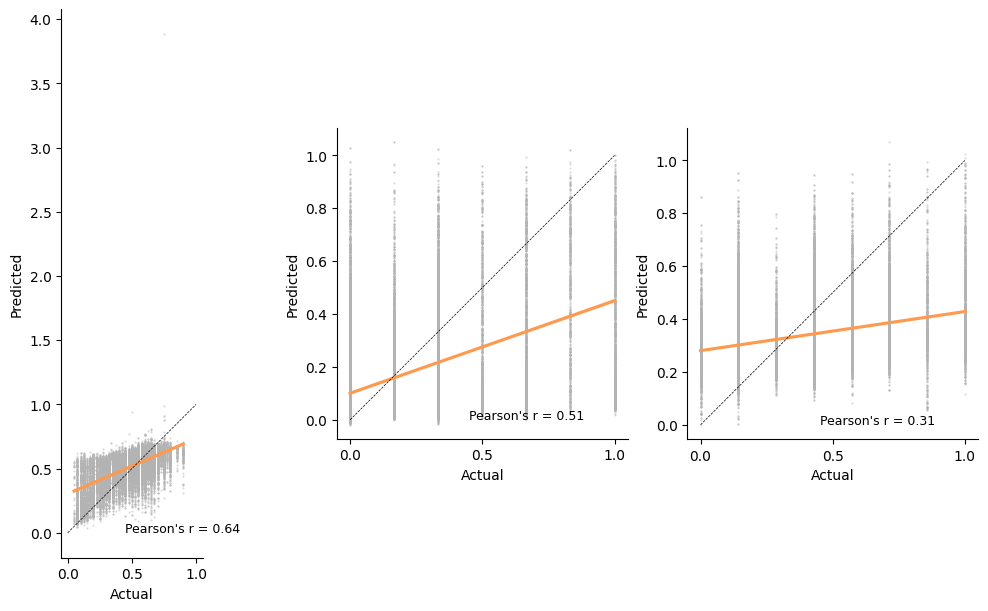

In [14]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

## Aggregation over an entire study

In [15]:
# Aggregation over time for a study

y = []
yp = []
maxsample = 1000000
running_pred = []
running_label = []
curr_acc = os.path.basename(os.path.split(eval_dataset.clips[0])[0])

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(eval_dataset), maxsample))):
        acc = os.path.basename(os.path.split(eval_dataset.clips[idx])[0])
        if acc != curr_acc:
            # print(running_label)
            # print(running_pred)
            y.append(running_label)
            yp.append(running_pred)
            running_pred = []
            running_label = []
            curr_acc = acc
            # print(running_label)
            # print(running_pred)
            # break
        
        running_pred.append(model(eval_dataset[idx]['data'].to(device)).cpu().numpy().squeeze())
        running_label.append(eval_dataset[idx]['label'].numpy().squeeze())
        # print(running_pred)
        # print(running_label)
        # break
        
# ymean = []
# ypmean = []
# for i in range(len(yp)):
#     ymean.append(np.mean(np.array(y[i]), axis=0))
#     ypmean.append(np.mean(np.array(yp[i]), axis=0))

# results = np.concatenate((np.array(ymean),np.array([np.mean(pred, axis=0) if len(pred.shape) == 2 else pred for pred in ypmean])), axis=1)
# df = pd.DataFrame(results, columns=[f'{feature}_label' for feature in features] + [f'{feature}_pred' for feature in features])

# df = df.drop(np.where(df['LVEF_label'] > 1)[0])

  2%|▏         | 1058/46064 [00:58<33:59, 22.07it/s] 

100%|██████████| 46064/46064 [42:17<00:00, 18.15it/s]  


In [16]:
clip_condensed_yp = []
for study in tqdm.tqdm(yp):
    study_condensed = []
    for clip in study:
        if len(clip.shape) > 1:
            study_condensed.append(np.mean(clip, axis=0))
        else:
            study_condensed.append(clip)
    clip_condensed_yp.append(study_condensed)

100%|██████████| 819/819 [00:00<00:00, 11618.02it/s]


In [17]:
len(clip_condensed_yp)

819

In [18]:
len(y)

819

In [19]:
ymean = []
ypmean = []
for i in range(len(clip_condensed_yp)):
    ymean.append(np.mean(np.array(y[i]), axis=0))
    ypmean.append(np.mean(np.array(clip_condensed_yp[i]), axis=0))

results = np.concatenate((np.array(ymean),np.array([np.mean(pred, axis=0) if len(pred.shape) == 2 else pred for pred in ypmean])), axis=1)
df = pd.DataFrame(results, columns=[f'{feature}_label' for feature in features] + [f'{feature}_pred' for feature in features])

df = df.drop(np.where(df['LVEF_label'] > 1)[0])

In [20]:
# # Aggregation over time for one study, broken into pre and post exam periods

# y_pre = []
# y_post = []
# yp_pre = []
# yp_post = []
# maxsample = 10000
# running_pred = []
# running_label = []
# curr_acc = os.path.basename(os.path.split(eval_dataset.clips[0])[0])
# curr_prepost = 0

# with torch.no_grad():
#     for idx in tqdm.tqdm(range(min(len(eval_dataset), maxsample))):
#         acc = os.path.basename(os.path.split(eval_dataset.clips[idx])[0])
#         prepost = eval_dataset[idx]['prepost']
#         if acc != curr_acc or prepost != curr_prepost:
#             y_pre.append(np.mean(running_label))
#             y_post.append(np.mean(running_label))
#             yp.append(np.mean(running_pred))
            
#             running_pred = []
#             running_label = []
#             curr_acc = acc
#             curr_prepost = prepost
        
#         running_pred.append(torch.mean(model(eval_dataset[idx]['data'].to(device))).item())
#         running_label.append(eval_dataset[idx]['label'])
        
# df = pd.DataFrame({'y':y, 'yp':yp})

Text(0.5, 1.0, 'TR')

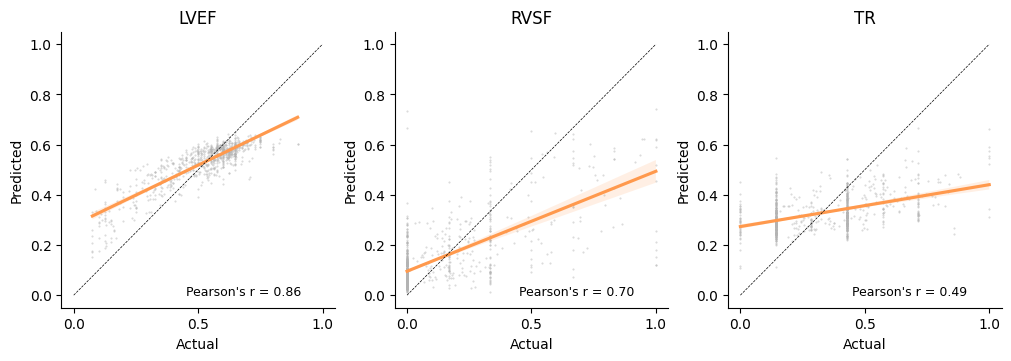

In [22]:
fig, ax = plt.subplots(1,3, figsize=(10,3.5), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    # a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)
ax[0].set_title('LVEF')

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)
ax[1].set_title('RVSF')

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)
ax[2].set_title('TR')

In [23]:
import itertools
from sklearn.metrics import auc, roc_curve, confusion_matrix, ConfusionMatrixDisplay


def plot_confusion_matrix(cm, classes, cm2, 
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar(shrink=0.8)
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=90, fontsize=11)
    plt.yticks(tick_marks, classes, fontsize=11)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm2[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black",
                 fontsize=11)

    # plt.tight_layout()
    plt.ylabel('True label', fontsize=11)
    plt.xlabel('Predicted label', fontsize=11)

In [24]:
y1 = (np.array(ymean)[:,1] * 6).round()
yp1 = (np.array(ypmean)[:,1] * 6).round()

y2 = (np.array(ymean)[:,2] * 7).round()
yp2 = (np.array(ypmean)[:,2] * 7).round()

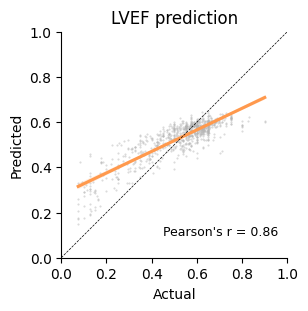

In [37]:
import seaborn as sns

fig, ax = plt.subplots(1,1, figsize=(3,3), layout="constrained")
ax.spines[['right', 'top']].set_visible(False)
ax.set_aspect('equal')
ax.set_xlim([0,1])
ax.set_ylim([0,1])

from scipy import stats
res = stats.pearsonr(labels[:,0], preds[:,0])
sns.regplot(x=labels[:,0], y=preds[:,0], marker='.', ax=ax, scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax.plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax.set_aspect('equal')
ax.set_ylabel('Predicted')
ax.set_xlabel('Actual')
ax.text(0.45,0.1,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)
ax.set_title('LVEF prediction')
plt.savefig('LV_EF_prediction_averaged.png', dpi=300)

Normalized confusion matrix
[[0.56046065 0.4049904  0.03071017 0.         0.00383877 0.
  0.        ]
 [0.1875     0.625      0.17857143 0.00892857 0.         0.
  0.        ]
 [0.12631579 0.47368421 0.29473684 0.10526316 0.         0.
  0.        ]
 [0.         0.42424242 0.33333333 0.21212121 0.03030303 0.
  0.        ]
 [0.03571429 0.21428571 0.25       0.35714286 0.14285714 0.
  0.        ]
 [0.         0.         0.4        0.53333333 0.06666667 0.
  0.        ]
 [0.         0.33333333 0.06666667 0.2        0.4        0.
  0.        ]]


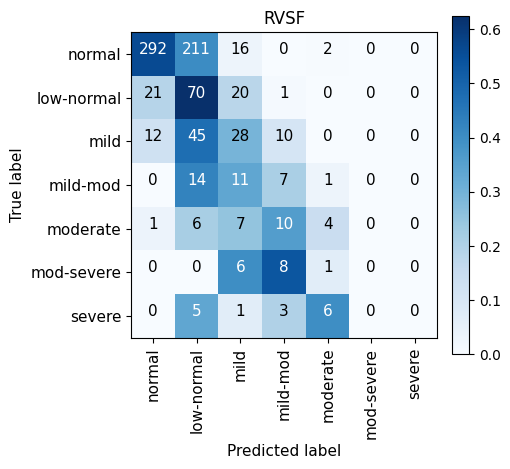

In [ ]:
class_names = ['normal','low-normal','mild','mild-mod','moderate','mod-severe','severe']
# class_names = ['absent','trace','trace-mild','mild','mild-moderate','moderate','moderate-severe','severe']

test_labels, test_labels_predicted = y1, yp1
    
# Compute confusion matrix
cm = confusion_matrix(test_labels, test_labels_predicted, normalize='true')
cm2 = confusion_matrix(test_labels, test_labels_predicted)

# Plot normalized confusion matrix
plt.figure(figsize = (5, 5), constrained_layout=True)
plot_confusion_matrix(cm=cm, classes=class_names, cm2=cm2, normalize=True,
                      title='RVSF')

plt.savefig('RVSF_prediction_confusion_matrix_averaged.png', dpi=300)

Normalized confusion matrix
[[0.         0.1        0.8        0.1        0.         0.
  0.         0.        ]
 [0.         0.01766784 0.83038869 0.14840989 0.00353357 0.
  0.         0.        ]
 [0.         0.         0.8452381  0.1547619  0.         0.
  0.         0.        ]
 [0.         0.         0.71863118 0.27376426 0.00760456 0.
  0.         0.        ]
 [0.         0.         0.35211268 0.63380282 0.01408451 0.
  0.         0.        ]
 [0.         0.         0.32758621 0.55172414 0.10344828 0.01724138
  0.         0.        ]
 [0.         0.         0.25       0.75       0.         0.
  0.         0.        ]
 [0.         0.         0.25       0.         0.625      0.125
  0.         0.        ]]


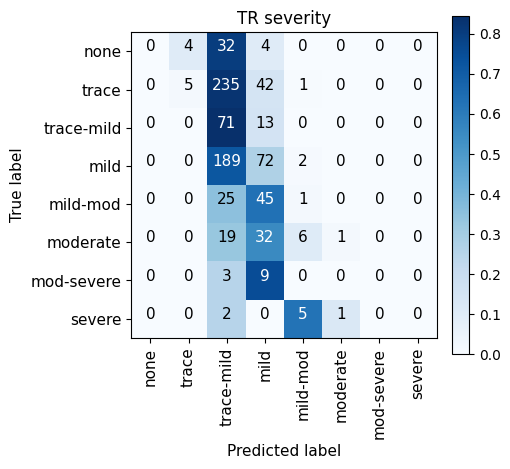

In [ ]:
# class_names = ['absent','trace','trace-mild','mild','mild-moderate','moderate','severe']
class_names = ['none','trace','trace-mild','mild','mild-mod','moderate','mod-severe','severe']

test_labels, test_labels_predicted = y2, yp2
    
# Compute confusion matrix
cm = confusion_matrix(test_labels, test_labels_predicted, normalize='true')
cm2 = confusion_matrix(test_labels, test_labels_predicted)

# Plot normalized confusion matrix
plt.figure(figsize = (5, 5), constrained_layout=True)
plot_confusion_matrix(cm=cm, classes=class_names, cm2=cm2, normalize=True,
                      title='TR severity')

plt.savefig('TR_prediction_confusion_matrix_averaged.png', dpi=300)

Logistic: ROC AUC=0.880
Logistic: ROC AUC=0.975
Logistic: ROC AUC=0.846
Logistic: ROC AUC=0.912
Logistic: ROC AUC=0.650
Logistic: ROC AUC=0.805


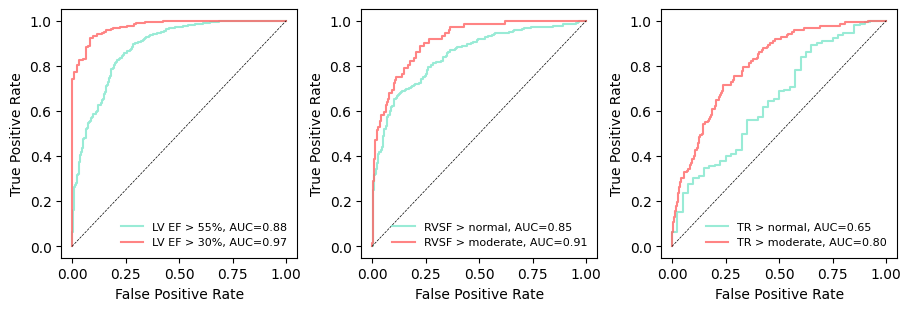

In [39]:
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

preds = np.concatenate((np.array(ypmean)[:,0].reshape(-1,1), np.array(ypmean)[:,1].reshape(-1,1), np.array(ypmean)[:,2].reshape(-1,1)), axis=1)
labels = np.concatenate((np.array(ymean)[:,0].reshape(-1,1), np.array(ymean)[:,1].reshape(-1,1), np.array(ymean)[:,2].reshape(-1,1)), axis=1)

fig, ax = plt.subplots(1,3, figsize=(9,3), layout="constrained")

y50 = [v > 0.55 for v in labels[:,0]]
y25 = [v > 0.30 for v in labels[:,0]]

testy, predy = y50, preds[:,0]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[0].plot(fpr, tpr, label='LV EF > 55%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

testy, predy = y25, preds[:,0]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[0].plot(fpr, tpr, label='LV EF > 30%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].legend(fontsize=8, frameon=False)
ax[0].set_ylabel('True Positive Rate')
ax[0].set_xlabel('False Positive Rate')
# ax[0].set_title('LVEF')


y50 = [v > 0.071 for v in labels[:,1]]
y25 = [v > 0.5 for v in labels[:,1]]

testy, predy = y50, preds[:,1]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='RVSF > normal, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

testy, predy = y25, preds[:,1]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='RVSF > moderate, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].legend(fontsize=8, frameon=False)
ax[1].set_ylabel('True Positive Rate')
ax[1].set_xlabel('False Positive Rate')
# ax[1].set_title('RVSF')


y50 = [v > 0.11 for v in labels[:,2]]
y25 = [v > 0.55 for v in labels[:,2]]

testy, predy = y50, preds[:,2]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[2].plot(fpr, tpr, label='TR > normal, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

testy, predy = y25, preds[:,2]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[2].plot(fpr, tpr, label='TR > moderate, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].legend(fontsize=8, frameon=False)
ax[2].set_ylabel('True Positive Rate')
ax[2].set_xlabel('False Positive Rate')
# ax[2].set_title('TR')

#add horizontal gap between plots
plt.savefig('ROC_curves_averaged.png', dpi=300)